<a href="https://colab.research.google.com/github/AnirudhRajesh09/BIS/blob/main/BIS_Pgm1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

WASTE COLLECTION ROUTE OPTIMIZATION
GENETIC ALGORITHM

Number of collection points : 10
Number of vehicles          : 2
Vehicle capacity            : 20
Total waste                 : 47

Initial random distance: 125.66
Generation   0 | Best Distance = 109.01
Generation  50 | Best Distance = 95.91
Generation 100 | Best Distance = 95.91
Generation 150 | Best Distance = 95.91
Generation 200 | Best Distance = 95.91
Generation 250 | Best Distance = 95.91
Generation 300 | Best Distance = 95.91
Generation 350 | Best Distance = 95.91
Generation 400 | Best Distance = 95.91
Generation 450 | Best Distance = 95.91

OPTIMIZED WASTE COLLECTION ROUTES

Vehicle 1
Route: Depot → Bin 3 → Bin 6 → Bin 4 → Bin 7 → Landfill → Depot
Waste collected : 18
Route distance  : 33.72

Vehicle 2
Route: Depot → Bin 8 → Bin 2 → Bin 5 → Bin 10 → Landfill → Depot
Waste collected : 20
Route distance  : 31.49

Vehicle 3
Route: Depot → Bin 1 → Bin 9 → Landfill → Depot
Waste collected : 9
Route distance  : 30.69

----------

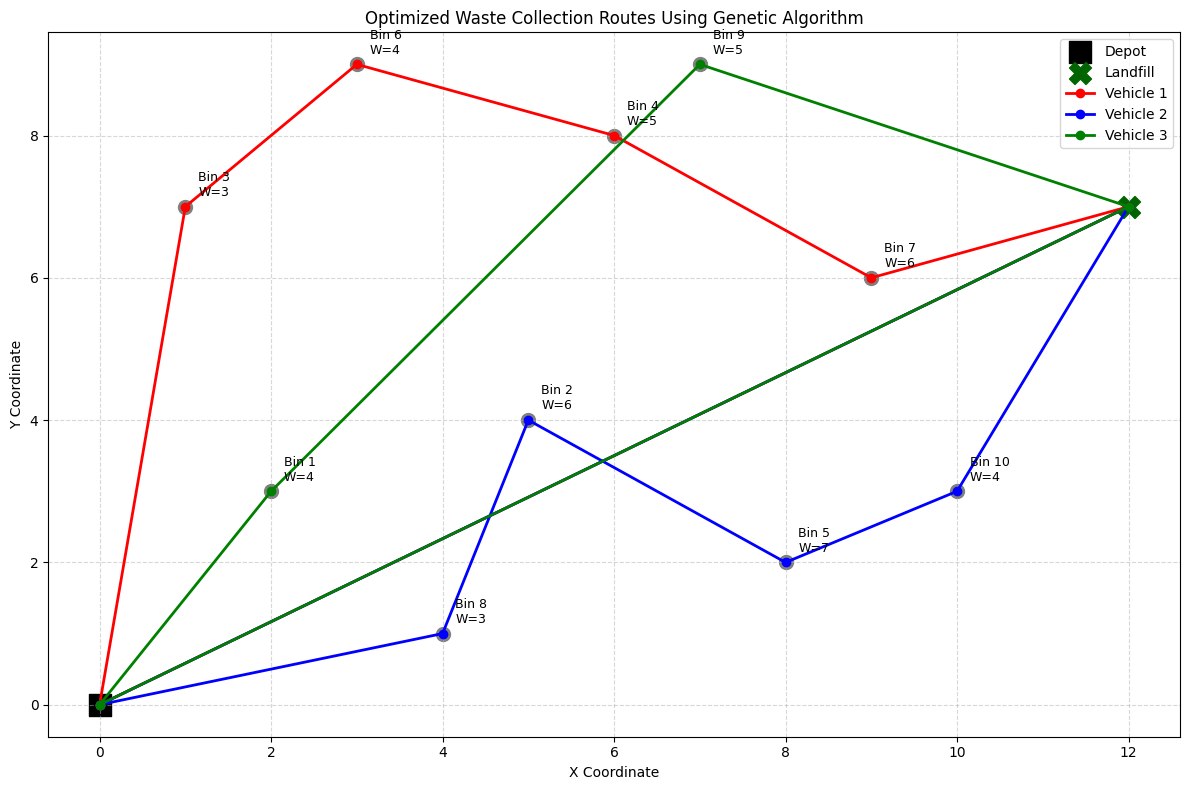

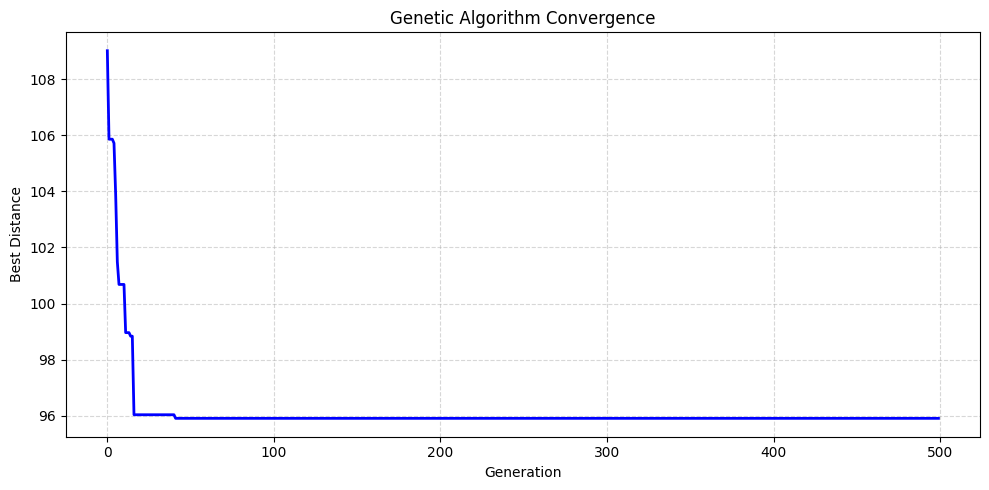

In [ ]:
import random
import math
import matplotlib.pyplot as plt


# ============================================================
# 1. PROBLEM DATA
# ============================================================

# Depot
DEPOT = 0

# Landfill / waste disposal point
LANDFILL = 11

# Waste collection points
#
# Format:
# ID : {
#     "x": x-coordinate,
#     "y": y-coordinate,
#     "waste": amount of waste
# }

locations = {

    0:  {"x": 0,  "y": 0,  "waste": 0},    # Depot

    1:  {"x": 2,  "y": 3,  "waste": 4},
    2:  {"x": 5,  "y": 4,  "waste": 6},
    3:  {"x": 1,  "y": 7,  "waste": 3},
    4:  {"x": 6,  "y": 8,  "waste": 5},
    5:  {"x": 8,  "y": 2,  "waste": 7},
    6:  {"x": 3,  "y": 9,  "waste": 4},
    7:  {"x": 9,  "y": 6,  "waste": 6},
    8:  {"x": 4,  "y": 1,  "waste": 3},
    9:  {"x": 7,  "y": 9,  "waste": 5},
    10: {"x": 10, "y": 3, "waste": 4},

    # Landfill
    11: {"x": 12, "y": 7, "waste": 0}
}


# ============================================================
# 2. VEHICLE INFORMATION
# ============================================================

NUMBER_OF_VEHICLES = 2

# Maximum amount of waste a vehicle can carry
VEHICLE_CAPACITY = 20


# ============================================================
# 3. GENETIC ALGORITHM PARAMETERS
# ============================================================

POPULATION_SIZE = 100

GENERATIONS = 500

MUTATION_RATE = 0.03

TOURNAMENT_SIZE = 5

ELITE_SIZE = 2


# ============================================================
# 4. BASIC DISTANCE FUNCTION
# ============================================================

def distance(point_a, point_b):

    x1 = locations[point_a]["x"]
    y1 = locations[point_a]["y"]

    x2 = locations[point_b]["x"]
    y2 = locations[point_b]["y"]

    return math.sqrt(
        (x2 - x1) ** 2 +
        (y2 - y1) ** 2
    )


# ============================================================
# 5. TOTAL WASTE
# ============================================================

customers = [
    location
    for location in locations
    if location not in [DEPOT, LANDFILL]
]


def total_waste():

    return sum(
        locations[customer]["waste"]
        for customer in customers
    )


# ============================================================
# 6. CREATE INITIAL POPULATION
# ============================================================

def create_population():

    population = []

    for _ in range(POPULATION_SIZE):

        chromosome = customers.copy()

        random.shuffle(chromosome)

        population.append(chromosome)

    return population


# ============================================================
# 7. SPLIT A CHROMOSOME INTO VEHICLE ROUTES
# ============================================================

def create_routes(chromosome):

    routes = []

    current_route = []
    current_load = 0

    for customer in chromosome:

        waste = locations[customer]["waste"]

        # If adding this customer exceeds capacity,
        # start another vehicle route.
        if (
            current_load + waste > VEHICLE_CAPACITY
            and current_route
        ):

            routes.append(current_route)

            current_route = []
            current_load = 0

        current_route.append(customer)

        current_load += waste

    # Add remaining route
    if current_route:

        routes.append(current_route)

    return routes


# ============================================================
# 8. ROUTE DISTANCE
# ============================================================

def calculate_route_distance(route):

    if not route:
        return 0

    total = 0

    # Start at depot
    previous = DEPOT

    # Visit collection points
    for customer in route:

        total += distance(previous, customer)

        previous = customer

    # Go to landfill
    total += distance(previous, LANDFILL)

    # Return to depot
    total += distance(LANDFILL, DEPOT)

    return total


# ============================================================
# 9. ROUTE WASTE LOAD
# ============================================================

def route_load(route):

    return sum(
        locations[customer]["waste"]
        for customer in route
    )


# ============================================================
# 10. FITNESS FUNCTION
# ============================================================

def fitness(chromosome):

    routes = create_routes(chromosome)

    total_distance = 0

    penalty = 0

    # --------------------------------------------------------
    # Check each vehicle route
    # --------------------------------------------------------

    for route in routes:

        load = route_load(route)

        route_distance = calculate_route_distance(route)

        total_distance += route_distance

        # Capacity violation penalty
        if load > VEHICLE_CAPACITY:

            excess = load - VEHICLE_CAPACITY

            penalty += excess * 1000

    # --------------------------------------------------------
    # Penalty if too many vehicles are required
    # --------------------------------------------------------

    if len(routes) > NUMBER_OF_VEHICLES:

        extra_vehicles = (
            len(routes) - NUMBER_OF_VEHICLES
        )

        penalty += extra_vehicles * 5000

    # --------------------------------------------------------
    # Final cost
    # --------------------------------------------------------

    total_cost = total_distance + penalty

    # GA maximizes fitness,
    # therefore convert minimization into maximization.

    return 1 / (1 + total_cost)


# ============================================================
# 11. TOURNAMENT SELECTION
# ============================================================

def selection(population):

    tournament = random.sample(
        population,
        TOURNAMENT_SIZE
    )

    winner = max(
        tournament,
        key=fitness
    )

    return winner.copy()


# ============================================================
# 12. ORDER CROSSOVER (OX)
# ============================================================

def crossover(parent1, parent2):

    size = len(parent1)

    # Choose two crossover positions
    start, end = sorted(
        random.sample(
            range(size),
            2
        )
    )

    # Create empty child
    child = [None] * size

    # Copy segment from parent 1
    child[start:end] = parent1[start:end]

    # Fill remaining genes using parent 2
    position = end

    for gene in parent2:

        if gene not in child:

            if position >= size:

                position = 0

            child[position] = gene

            position += 1

    return child


# ============================================================
# 13. MUTATION
# ============================================================

def mutation(chromosome):

    chromosome = chromosome.copy()

    for i in range(len(chromosome)):

        if random.random() < MUTATION_RATE:

            j = random.randint(
                0,
                len(chromosome) - 1
            )

            # Swap two collection points
            chromosome[i], chromosome[j] = (
                chromosome[j],
                chromosome[i]
            )

    return chromosome


# ============================================================
# 14. GENETIC ALGORITHM
# ============================================================

def genetic_algorithm():

    # --------------------------------------------------------
    # Initial population
    # --------------------------------------------------------

    population = create_population()

    best_solution = None

    best_cost = float("inf")

    history = []

    # --------------------------------------------------------
    # GA generations
    # --------------------------------------------------------

    for generation in range(GENERATIONS):

        # Sort according to fitness
        population.sort(
            key=fitness,
            reverse=True
        )

        # Current best solution
        current_best = population[0]

        current_routes = create_routes(
            current_best
        )

        current_cost = sum(
            calculate_route_distance(route)
            for route in current_routes
        )

        # Save global best
        if current_cost < best_cost:

            best_cost = current_cost

            best_solution = (
                current_best.copy()
            )

        history.append(best_cost)

        # ----------------------------------------------------
        # Create new population
        # ----------------------------------------------------

        new_population = []

        # Elitism
        for i in range(ELITE_SIZE):

            new_population.append(
                population[i].copy()
            )

        # Generate children
        while len(new_population) < POPULATION_SIZE:

            parent1 = selection(population)

            parent2 = selection(population)

            child = crossover(
                parent1,
                parent2
            )

            child = mutation(child)

            new_population.append(child)

        population = new_population

        # ----------------------------------------------------
        # Display progress
        # ----------------------------------------------------

        if generation % 50 == 0:

            print(
                f"Generation {generation:3d} | "
                f"Best Distance = {best_cost:.2f}"
            )

    return (
        best_solution,
        best_cost,
        history
    )


# ============================================================
# 15. DISPLAY ROUTES
# ============================================================

def display_routes(chromosome):

    routes = create_routes(chromosome)

    print("\n" + "=" * 60)

    print("OPTIMIZED WASTE COLLECTION ROUTES")

    print("=" * 60)

    total_distance = 0
    total_collected = 0

    for i, route in enumerate(routes):

        load = route_load(route)

        distance_value = calculate_route_distance(
            route
        )

        total_distance += distance_value

        total_collected += load

        print(
            f"\nVehicle {i + 1}"
        )

        print(
            "Route: Depot → ",
            end=""
        )

        for customer in route:

            print(
                f"Bin {customer} → ",
                end=""
            )

        print("Landfill → Depot")

        print(
            f"Waste collected : {load}"
        )

        print(
            f"Route distance  : "
            f"{distance_value:.2f}"
        )

    print("\n" + "-" * 60)

    print(
        f"Total waste collected : "
        f"{total_collected}"
    )

    print(
        f"Total distance        : "
        f"{total_distance:.2f}"
    )

    print(
        f"Vehicles used         : "
        f"{len(routes)}"
    )

    print("-" * 60)


# ============================================================
# 16. CALCULATE INITIAL RANDOM SOLUTION
# ============================================================

def initial_solution():

    chromosome = customers.copy()

    random.shuffle(chromosome)

    routes = create_routes(chromosome)

    total_distance = sum(
        calculate_route_distance(route)
        for route in routes
    )

    return chromosome, total_distance


# ============================================================
# 17. VISUALIZE ROUTES
# ============================================================

def plot_routes(chromosome):

    routes = create_routes(chromosome)

    colors = [
        "red",
        "blue",
        "green",
        "orange",
        "purple",
        "brown"
    ]

    plt.figure(
        figsize=(12, 8)
    )

    # --------------------------------------------------------
    # Plot depot
    # --------------------------------------------------------

    plt.scatter(
        locations[DEPOT]["x"],
        locations[DEPOT]["y"],
        s=250,
        marker="s",
        color="black",
        label="Depot"
    )

    # --------------------------------------------------------
    # Plot landfill
    # --------------------------------------------------------

    plt.scatter(
        locations[LANDFILL]["x"],
        locations[LANDFILL]["y"],
        s=250,
        marker="X",
        color="darkgreen",
        label="Landfill"
    )

    # --------------------------------------------------------
    # Plot waste bins
    # --------------------------------------------------------

    for customer in customers:

        x = locations[customer]["x"]

        y = locations[customer]["y"]

        waste = locations[customer]["waste"]

        plt.scatter(
            x,
            y,
            s=100,
            color="gray"
        )

        plt.text(
            x + 0.15,
            y + 0.15,
            f"Bin {customer}\n"
            f"W={waste}",
            fontsize=9
        )

    # --------------------------------------------------------
    # Plot each vehicle route
    # --------------------------------------------------------

    for i, route in enumerate(routes):

        color = colors[i % len(colors)]

        # Depot → customers → landfill → depot

        complete_route = (
            [DEPOT]
            + route
            + [LANDFILL]
            + [DEPOT]
        )

        x_values = [
            locations[node]["x"]
            for node in complete_route
        ]

        y_values = [
            locations[node]["y"]
            for node in complete_route
        ]

        plt.plot(
            x_values,
            y_values,
            color=color,
            linewidth=2,
            marker="o",
            label=f"Vehicle {i + 1}"
        )

    plt.title(
        "Optimized Waste Collection Routes "
        "Using Genetic Algorithm"
    )

    plt.xlabel("X Coordinate")

    plt.ylabel("Y Coordinate")

    plt.grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 18. PLOT GA CONVERGENCE
# ============================================================

def plot_convergence(history):

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history,
        color="blue",
        linewidth=2
    )

    plt.title(
        "Genetic Algorithm Convergence"
    )

    plt.xlabel(
        "Generation"
    )

    plt.ylabel(
        "Best Distance"
    )

    plt.grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 19. MAIN PROGRAM
# ============================================================

if __name__ == "__main__":

    print("=" * 60)

    print(
        "WASTE COLLECTION ROUTE OPTIMIZATION"
    )

    print(
        "GENETIC ALGORITHM"
    )

    print("=" * 60)

    print(
        f"\nNumber of collection points : "
        f"{len(customers)}"
    )

    print(
        f"Number of vehicles          : "
        f"{NUMBER_OF_VEHICLES}"
    )

    print(
        f"Vehicle capacity            : "
        f"{VEHICLE_CAPACITY}"
    )

    print(
        f"Total waste                 : "
        f"{total_waste()}"
    )

    # --------------------------------------------------------
    # Initial random solution
    # --------------------------------------------------------

    initial_route, initial_distance = (
        initial_solution()
    )

    print(
        f"\nInitial random distance: "
        f"{initial_distance:.2f}"
    )

    # --------------------------------------------------------
    # Run Genetic Algorithm
    # --------------------------------------------------------

    best_route, best_distance, history = (
        genetic_algorithm()
    )

    # --------------------------------------------------------
    # Display final result
    # --------------------------------------------------------

    display_routes(
        best_route
    )

    print(
        f"\nInitial distance : "
        f"{initial_distance:.2f}"
    )

    print(
        f"Optimized distance: "
        f"{best_distance:.2f}"
    )

    improvement = (
        (initial_distance - best_distance)
        / initial_distance
        * 100
    )

    print(
        f"Improvement      : "
        f"{improvement:.2f}%"
    )

    # --------------------------------------------------------
    # Plot routes
    # --------------------------------------------------------

    plot_routes(
        best_route
    )

    # --------------------------------------------------------
    # Plot convergence
    # --------------------------------------------------------

    plot_convergence(
        history
    )